# 04. Steady-state $S_{21}$: the virtual VNA against the measurement

A frequency sweep at fixed flux and power is the simplest test of the model and the first measurement every
multiplexer channel gets. This notebook builds the virtual device of resonator 2 from its configuration file, sweeps
a probe tone across the resonance with the coupled-mode solver, and compares the result with the measured trace that
the configuration was extracted from (paper Sec. V A, Fig. 6). Data: the VNA flux-power sweep
`data/vna/res2_flux_power_sweep_2026-09-26.npz` at $-26$ dBm VNA output and zero flux bias, and the configuration
`configs/nist_res2_2026-09-26.toml`. It runs in under 10 s, half of it the timing in Step 6.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time

SWEEP = DATA / "vna" / "res2_flux_power_sweep_2026-09-26.npz"
CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
P_VNA = -26.0                     # dBm at the VNA output, the power the configuration was extracted at
FLUX_IDX = 0                      # the trace at zero flux bias
M_NOMINAL = 14.4e-12              # H, the flux axis of the sweep is in Phi0 at this design mutual
atten = store.value("Atten", default=-62.9)    # dB from the VNA output to the chip, fitted in notebook 05

## 1. The measured trace

The sweep holds $S_{21}$ at 16 VNA powers, 101 flux biases and 1001 frequencies; we take the trace at $-26$ dBm VNA
output and zero flux bias, where with the line attenuation $A$ fitted in notebook 05 the power at the chip is
$P_\mathrm{chip} = -26\,\mathrm{dBm} + A \approx -89$ dBm. `fit_resonance_trace` removes the cable delay $\tau$ with
a line through the phase of the two 1.2 MHz edge bands of the sweep (fitted with the notch divided out, iterated until
$\tau$ converges) and fits the notch $1 - e^{i\alpha}(Q_r/|Q_c|)/[1 + 2iQ_r(f-f_r)/f_r]$ times a complex baseline
$a\,e^{i\phi_\mathrm{bg}}$ within $\pm1.5$ MHz of the dip, with the circle method of Probst et al. Dividing the
delay-corrected trace by $a$ normalises it to $|S_{21}| \to 1$ off resonance, the scale of the model; its phase
reference is the delay line, and the small fitted $\phi_\mathrm{bg}$ is left in. These fitted numbers belong to this
one trace: they only normalise the data and set the window and scale of the comparison.

In [2]:
sweep = uc.load_vna_sweep(SWEEP)
k = sweep.power_index(P_VNA)
P_chip = sweep.powers[k] + atten
f, s21_raw = sweep.f, sweep.s21[k, FLUX_IDX]
I_bias = sweep.bias_current(M_NOMINAL)[FLUX_IDX]

meas = uc.fitting.fit_resonance_trace(f, s21_raw)
s21_meas = meas.s21_corrected / meas.a

print(f"sweep {sweep.shape} (power, flux, frequency); this trace: {sweep.powers[k]:.0f} dBm at the VNA = "
      f"{P_chip:.1f} dBm at the chip, flux bias {sweep.flux[FLUX_IDX]:.2f} Phi0 (I = {I_bias * 1e6:.1f} uA)")
print(f"delay {meas.tau * 1e9:.2f} ns after {meas.n_iter} iterations, a = {meas.a:.4f}, phi_bg = {meas.bg_phase:.3f} rad\n")
print(f"{'fr (MHz)':>11} {'Qr':>6} {'|Qc|':>6} {'alpha':>8} {'fr/Qr (kHz)':>12}")
print(f"{meas.fr / 1e6:11.4f} {meas.Qr:6.0f} {meas.Qc_abs:6.0f} {meas.alpha:8.4f} {meas.linewidth / 1e3:12.0f}")

sweep (16, 101, 1001) (power, flux, frequency); this trace: -26 dBm at the VNA = -88.9 dBm at the chip, flux bias 0.00 Phi0 (I = 0.0 uA)
delay 87.03 ns after 4 iterations, a = 0.0318, phi_bg = 0.011 rad

   fr (MHz)     Qr   |Qc|    alpha  fr/Qr (kHz)
  5515.9585   9595  10505  -0.0875          575


## 2. The virtual device

`load_config` builds the channel from parameters fitted to this same sweep at this same power in notebook 01 ($Q_r$,
$|Q_c|$, $\alpha$: the medians of the circle fits over its 101 flux points; $f_0$, $\lambda$, $M_c$, $M_\mathrm{fr}$,
trapped flux: the fit of $f_r$ against bias current), with $L_s = 24.2$ pH, $L_c$ and $M_\mathrm{in}$ held fixed, so
the comparison is a consistency check of configuration and solver, not a prediction. The channel keeps the coupling
as the diameter-correction-method $Q_c = |Q_c|/\cos\alpha$, the `Qc` column of the summary; the circle fits, and the
tables below, give $|Q_c|$. Because $\lambda$ and $M_c$ were fitted at $-89$ dBm they already carry the RF dressing of the
SQUID at that power, and the CMT dresses it once more from the stored energy (Step 5 measures the effect). We put the
trace's bias current on the flux-ramp line; the model's resonance there in the low-power limit,
$f_r = \omega_r(\Phi, E_r{=}0)/2\pi$, is the reference of all frequency axes below.

In [3]:
device = uc.load_config(CONFIG)
ch = device[0]
ch.line("FluxRamp").I = I_bias
fr_model = ch.get_fr(0.0)

print(device.summary())
print(f"\nat this bias, Er = 0: fr = {fr_model / 1e6:.4f} MHz, {(fr_model - meas.fr) / 1e3:+.1f} kHz from the measured fr")
print(f"kappa/2pi = {ch.linewidth / 1e3:.0f} kHz, ring-up time 2/kappa = {ch.ring_up_time * 1e9:.0f} ns")

nist_res2_2026-09-26: 1 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5515.689    9515   10475    103803  -0.086  0.318     3.69       580

at this bias, Er = 0: fr = 5515.9547 MHz, -3.8 kHz from the measured fr
kappa/2pi = 580 kHz, ring-up time 2/kappa = 549 ns


## 3. The virtual VNA

At each probe frequency `steady_state_sweep` integrates
$\dot a = -\left(i\Delta(t, |a|^2) + \kappa/2\right) a + \sqrt{\kappa_c/2}\,a_\mathrm{in}$ for a fixed time,
$20/\kappa \approx 5.5\,\mu$s from an empty cavity for the first point and $8/\kappa \approx 2.2\,\mu$s from the
previous point's field after that, and reads off $S_{21} = 1 - (e^{i\alpha}/\cos\alpha)\sqrt{\kappa_c/2}\;a/a_\mathrm{in}$
at the end. The detuning is re-evaluated at every time step from the stored energy $|a|^2$, so the sweep carries the
power dependence of the SQUID. These are the settings the paper used; Step 5 checks how well the field settles with
them. The 1201 points over $\pm3$ MHz take about a second.

In [4]:
f_sim = np.linspace(fr_model - 3e6, fr_model + 3e6, 1201)

t0 = time.perf_counter()
s21_sim = uc.steady_state_sweep(device, f_sim, P_chip, flux_ramp_current=I_bias)
print(f"{len(f_sim)} points at {P_chip:.1f} dBm in {time.perf_counter() - t0:.2f} s")

store.record("frSim", fr_model / 1e6, "{:.3f}", "MHz, model resonance at zero flux bias, 09/26 configuration (04)")
store.record("NSfreq", len(f_sim), "{:d}", "frequency points of the steady-state sweep (04)")
print(f"recorded: frSim {store.text('frSim')} MHz, NSfreq {store.text('NSfreq')}")

1201 points at -88.9 dBm in 0.74 s
recorded: frSim 5515.955 MHz, NSfreq 1201


## 4. Measurement and model side by side

The gist of Fig. 6: $|S_{21}|$ in dB with the resonance circle as an inset, the measured minus the simulated
$|S_{21}|$ in dB, and the delay-corrected phase. Nothing in the model was adjusted for this plot.

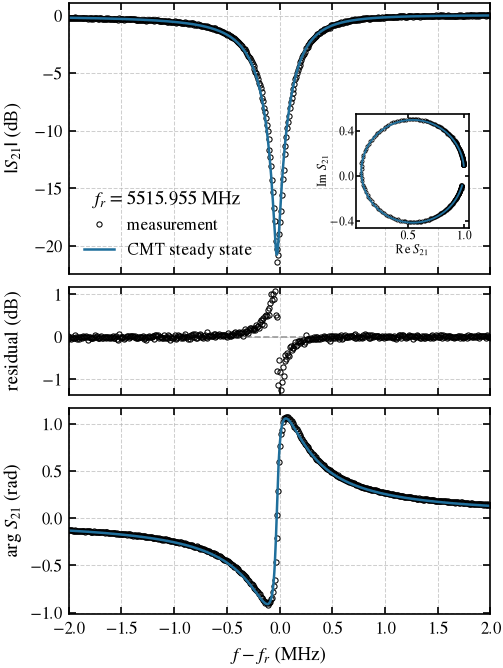

In [5]:
def interp_complex(f_out, f_in, z):
    return np.interp(f_out, f_in, z.real) + 1j * np.interp(f_out, f_in, z.imag)


win = np.abs(f - fr_model) < 3e6
x_meas, x_sim = (f[win] - fr_model) / 1e6, (f_sim - fr_model) / 1e6
s_meas = s21_meas[win]
dB = lambda z: 20 * np.log10(np.abs(z))
dots = dict(ls="none", marker="o", mfc="none", color=MEASURED, mew=0.5, ms=2.5)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(SINGLE, 4.5), sharex=True,
                                    gridspec_kw={"height_ratios": [2.5, 1, 1.9]})
ax1.plot(x_meas, dB(s_meas), label="measurement", **dots)
ax1.plot(x_sim, dB(s21_sim), color=BLUE, label="CMT steady state")
ax1.set_ylabel(r"$|S_{21}|$ (dB)")
ax1.legend(loc="lower left", title=rf"$f_r = {fr_model / 1e6:.3f}$ MHz")

iq = ax1.inset_axes([0.66, 0.17, 0.31, 0.42])
iq.plot(s_meas.real, s_meas.imag, **(dots | dict(mew=0.4, ms=1.5)))
iq.plot(s21_sim.real, s21_sim.imag, color=BLUE, lw=0.9)
iq.set_aspect("equal")
iq.set_xticks([0.5, 1])
iq.set_yticks([-0.4, 0, 0.4])
iq.tick_params(labelsize=6, length=2, pad=1)
iq.set_xlabel(r"Re $S_{21}$", fontsize=6, labelpad=1)
iq.set_ylabel(r"Im $S_{21}$", fontsize=6, labelpad=0)

ax2.axhline(0, color=ZERO, ls="--", lw=0.8)
ax2.plot(x_meas, dB(s_meas) - dB(interp_complex(f[win], f_sim, s21_sim)), **dots)
ax2.set_ylabel("residual (dB)")

ax3.plot(x_meas, np.angle(s_meas), **dots)
ax3.plot(x_sim, np.angle(s21_sim), color=BLUE)
ax3.set_ylabel(r"arg $S_{21}$ (rad)")
ax3.set_xlabel(r"$f - f_r$ (MHz)")
ax3.set_xlim(-2, 2)

for ax in (ax1, ax2, ax3):
    grid(ax)
fig.align_ylabels()
save(fig, "04_s21_cmt_vs_measurement", RESULTS / "figures")
plt.show()

## 5. Residuals and fitted parameters

Within $\pm1.5$ MHz of the measured $f_r$ (the window of the circle fit) we quote the rms of
$|S_{21,\mathrm{meas}} - S_{21,\mathrm{model}}|$ in units of the circle diameter $Q_r/|Q_c|$, the scale notebook 07
uses as well, for three cases: the CMT sweep, which has no free parameter; the free notch fit, whose four shape
parameters were adjusted to this trace; and the VNA noise, the rms point-to-point difference in the two edge bands
divided by $\sqrt2$. The recorded numbers normalise the trace by $a$ alone, as the paper does; a second column also
divides out the fitted baseline phase $\phi_\mathrm{bg}$.

In [6]:
w = np.abs(f - meas.fr) < 1.5e6
diam = meas.Qr / meas.Qc_abs
s_cmt = interp_complex(f[w], f_sim, s21_sim)
s_fit = uc.fitting.notch_model(f[w], meas.fr, meas.Qr, meas.Qc_abs, meas.alpha)
s_meas_bg = s21_meas[w] * np.exp(-1j * meas.bg_phase)
steps = np.concatenate([np.diff(s21_meas[band]) for band in (f < f[0] + 1.2e6, f > f[-1] - 1.2e6)])

res_cmt = uc.analysis.rms_distance(s21_meas[w], s_cmt, scale=diam)
res_cmt_max = np.abs(s21_meas[w] - s_cmt).max() / diam
res_fit = uc.analysis.rms_distance(s21_meas[w], s_fit, scale=diam)
noise = np.sqrt(np.mean(np.abs(steps) ** 2)) / np.sqrt(2) / diam

print(f"rms |S21_meas - S21_model| within +-1.5 MHz of fr, in units of the diameter Qr/|Qc| = {diam:.3f}:")
print(f"{'':<17}{'S21/a':>8}{'S21/(a e^i phi_bg)':>21}")
print(f"{'CMT sweep':<17}{res_cmt:8.2%}{uc.analysis.rms_distance(s_meas_bg, s_cmt, scale=diam):21.2%}"
      f"   (largest {res_cmt_max:.2%})")
print(f"{'free notch fit':<17}{res_fit:8.2%}{uc.analysis.rms_distance(s_meas_bg, s_fit, scale=diam):21.2%}")
print(f"{'VNA noise':<17}{noise:8.2%}{noise:21.2%}")

store.record("SResRel", 100 * res_cmt, "{:.1f}", "% of the circle diameter: rms CMT residual within +-1.5 MHz (04)")
store.record("SResRelMax", 100 * res_cmt_max, "{:.1f}", "% of the circle diameter: largest CMT residual (04)")
store.record("SFitRel", 100 * res_fit, "{:.1f}", "% of the circle diameter: rms residual of the free notch fit (04)")
store.record("SNoiseRel", 100 * noise, "{:.2f}", "% of the circle diameter: VNA noise from the edge bands (04)")
names = ("SResRel", "SResRelMax", "SFitRel", "SNoiseRel")
print("\nrecorded: " + ", ".join(f"{name} {store.text(name)}" for name in names))

rms |S21_meas - S21_model| within +-1.5 MHz of fr, in units of the diameter Qr/|Qc| = 0.913:
                    S21/a   S21/(a e^i phi_bg)
CMT sweep           1.52%                0.98%   (largest 2.77%)
free notch fit      1.11%                0.49%
VNA noise           0.38%                0.38%

recorded: SResRel 1.5, SResRelMax 2.8, SFitRel 1.1, SNoiseRel 0.38


Most of what the free notch fit leaves is the baseline phase of Step 1, $\phi_\mathrm{bg} = 0.011$ rad: inside the
fit window the trace is turned by that angle from the phase reference of the edge bands, and neither model has it.
Divided out, the free fit leaves 0.49% against 0.38% of noise, and the CMT 0.98%. The rest of the gap between them is
the CMT's resonance frequency. To take it apart, the simulated sweep is circle-fitted with the same notch fit
(`fit_resonance` is `refined_fit` returning a `NotchFit`; there is no delay to remove), and so is the same sweep run
downward: a field that has not quite settled lags behind the sweep, so a numerical lag changes sign with the sweep
direction while the physics does not.

In [7]:
s21_down = uc.steady_state_sweep(device, f_sim[::-1], P_chip, flux_ramp_current=I_bias)[::-1]
up, down = uc.fitting.fit_resonance(f_sim, s21_sim), uc.fitting.fit_resonance(f_sim, s21_down)
fr_settled = (up.fr + down.fr) / 2
Qc_config = ch.Qc * np.cos(ch.alpha)

rows = [("this trace, circle fit", meas.fr, meas.Qr, meas.Qc_abs, meas.alpha),
        ("configuration, Er = 0", fr_model, ch.Qr, Qc_config, ch.alpha),
        ("CMT sweep up (Step 3)", up.fr, up.Qr, up.Qc_abs, up.alpha),
        ("CMT sweep down", down.fr, down.Qr, down.Qc_abs, down.alpha)]
print(f"{'':<24}{'fr - fr_meas (kHz)':>19}{'Qr':>7}{'|Qc|':>7}{'alpha':>9}")
for name, fr_, Qr_, Qc_, alpha_ in rows:
    print(f"{name:<24}{(fr_ - meas.fr) / 1e3:19.1f}{Qr_:7.0f}{Qc_:7.0f}{alpha_:9.4f}")

lw = ch.linewidth
print(f"\nfr of the CMT sweep: {(up.fr - meas.fr) / 1e3:+.1f} kHz = {(up.fr - meas.fr) / lw:+.2%} of the "
      f"{lw / 1e3:.0f} kHz linewidth from this trace, made of")
print(f"  {(fr_model - meas.fr) / 1e3:+5.1f} kHz  flux-response fit at Er = 0, minus this trace")
print(f"  {(fr_settled - fr_model) / 1e3:+5.1f} kHz  second RF dressing at {P_chip:.1f} dBm: "
      f"mean of the two sweeps minus Er = 0")
print(f"  {(up.fr - fr_settled) / 1e3:+5.1f} kHz  settling lag: half the difference between the two sweeps")
Er_res = abs(uc.steady_state_field(0.0, ch.kappa, ch.get_kappa_c(), uc.dbm_to_field(P_chip))) ** 2
print(f"on resonance the cavity stores Er = {Er_res:.2e} J, which alone moves fr by "
      f"{(ch.get_fr(Er_res) - fr_model) / 1e3:+.2f} kHz")
print(f"Qr and |Qc| of the CMT sweep: {up.Qr / ch.Qr - 1:+.3%} and {up.Qc_abs / Qc_config - 1:+.3%} from the "
      f"configuration; Qr {up.Qr / meas.Qr - 1:+.2%} from this trace")

s_down = interp_complex(f[w], f_sim, s21_down)
s_moved = interp_complex(f[w], f_sim + (meas.fr - up.fr), s21_sim)
print(f"\nCMT residual swept down: {uc.analysis.rms_distance(s21_meas[w], s_down, scale=diam):.2%} "
      f"(largest {np.abs(s21_meas[w] - s_down).max() / diam:.2%}), against {res_cmt:.2%} ({res_cmt_max:.2%}) swept up")
print(f"CMT sweep moved onto the measured fr: {uc.analysis.rms_distance(s21_meas[w], s_moved, scale=diam):.2%}, "
      f"{uc.analysis.rms_distance(s_meas_bg, s_moved, scale=diam):.2%} with phi_bg divided out")

store.record("SfrOff", (up.fr - meas.fr) / 1e3, "{:.1f}", "kHz, circle-fitted fr of the CMT sweep minus the measured fr (04)")
store.record("SfrOffLw", 100 * (up.fr - meas.fr) / lw, "{:.1f}", "% of the linewidth, the same offset (04)")
store.record("SQrOff", 100 * (up.Qr / meas.Qr - 1), "{:.1f}", "%, circle-fitted Qr of the CMT sweep relative to the measured Qr (04)")
print("\nrecorded: " + ", ".join(f"{name} {store.text(name)}" for name in ("SfrOff", "SfrOffLw", "SQrOff")))

                         fr - fr_meas (kHz)     Qr   |Qc|    alpha
this trace, circle fit                  0.0   9595  10505  -0.0875
configuration, Er = 0                  -3.8   9515  10436  -0.0864
CMT sweep up (Step 3)                  -6.7   9515  10437  -0.0865
CMT sweep down                         -7.6   9515  10437  -0.0845

fr of the CMT sweep: -6.7 kHz = -1.16% of the 580 kHz linewidth from this trace, made of
   -3.8 kHz  flux-response fit at Er = 0, minus this trace
   -3.4 kHz  second RF dressing at -88.9 dBm: mean of the two sweeps minus Er = 0
   +0.5 kHz  settling lag: half the difference between the two sweeps
on resonance the cavity stores Er = 6.43e-19 J, which alone moves fr by -3.41 kHz
Qr and |Qc| of the CMT sweep: +0.006% and +0.013% from the configuration; Qr -0.83% from this trace

CMT residual swept down: 1.53% (largest 2.94%), against 1.52% (2.77%) swept up
CMT sweep moved onto the measured fr: 1.03%, 0.51% with phi_bg divided out

recorded: SfrOff -6.7, Sfr

Circle-fitting the virtual VNA returns the configuration's $Q_r$ and $|Q_c|$ to 0.02%, so the solver reproduces its
input; the $-0.8\%$ in $Q_r$ is the scatter of this one trace about the median of the 101 flux points. The $f_r$
offset has three parts. The flux-response fit, fitted to all 101 flux points, puts the low-power resonance 3.8 kHz
below this trace. The second dressing at $-89$ dBm moves the settled resonance down by another 3.4 kHz (0.6% of the
linewidth), the shift that the energy stored on resonance gives on its own. And the upward sweep lands 0.5 kHz above
the settled resonance: with the settings of the paper, $8/\kappa$ per point and an absolute tolerance of
$10^{-9}\sqrt{\mathrm J}$, above the on-resonance field of $8\times10^{-10}\sqrt{\mathrm J}$, the field lags behind
the sweep. Moved onto the measured $f_r$, the CMT leaves what the free fit leaves (0.51% against 0.49% with
$\phi_\mathrm{bg}$ divided out).

The recorded offset is that of the upward sweep, as in the paper; the settled resonance sits 7.2 kHz below the
trace, and `steady_state_sweep(..., settle_next=20, rtol=1e-8, atol=1e-15)` lands on it in either direction, in
about 12 s. The lag hardly changes the rms residual, but it moves the largest one between 2.8% (up) and 2.9% (down).
The settled line also has a 1% smaller $|\alpha|$ than the configuration: the dressing, strongest on resonance, makes
the line slightly asymmetric and the notch fit absorbs part of that in $\alpha$, which the lag of the upward sweep
happens to cancel.

## 6. Run time

Each frequency point costs one short integration, so the virtual VNA is cheap. The sweep of Step 3 is repeated five
times and the median wall time is quoted per point; a CPU time equal to the wall time shows that it runs on one core.
The numbers depend on the machine (the paper quotes 0.74 ms per point). This step takes about 4 s.

In [8]:
def median_run_time(fn, repeats=5):
    wall, cpu = [], []
    for _ in range(repeats):
        t0, c0 = time.perf_counter(), time.process_time()
        fn()
        wall.append(time.perf_counter() - t0)
        cpu.append(time.process_time() - c0)
    return float(np.median(wall)), float(np.median(cpu))


wall, cpu = median_run_time(lambda: uc.steady_state_sweep(device, f_sim, P_chip, flux_ramp_current=I_bias))
print(f"{len(f_sim)}-point sweep: {wall:.2f} s wall (median of 5), {wall / len(f_sim) * 1e3:.2f} ms per point, "
      f"CPU/wall = {cpu / wall:.2f}")

store.record("TimeSweep", wall, "{:.1f}", "s, wall time of the 1201-point steady-state sweep, median of 5 runs (04)")
store.record("TimePoint", wall / len(f_sim) * 1e3, "{:.2f}", "ms per frequency point of the steady-state sweep (04)")
print(f"recorded: TimeSweep {store.text('TimeSweep')} s, TimePoint {store.text('TimePoint')} ms")

1201-point sweep: 0.74 s wall (median of 5), 0.62 ms per point, CPU/wall = 1.00
recorded: TimeSweep 0.7 s, TimePoint 0.62 ms


## What to try next

- **Another flux bias or power.** `FLUX_IDX = 25` is $0.5\,\Phi_0$ (nominal), where the resonance sits about 450 kHz
  lower; the bias current is read from the sweep and put on the flux-ramp line, so the model follows with no other
  change. `P_VNA = -10` drives the SQUID hard: the dip moves about 180 kHz below the low-power $f_r$ and turns
  asymmetric, the free notch fit degrades to about 7% of the circle diameter, and the CMT, with the attenuation of
  notebook 05, stays near 1.3%. There the fitted $\phi_\mathrm{bg}$ grows to 0.07 rad because the ideal notch uses it
  to absorb part of the asymmetry, so dividing it out no longer isolates the baseline.
- **The other day.** Set `SWEEP = DATA / "vna" / "res2_flux_sweep_2026-10-04.npz"`, `P_VNA = -25` and
  `CONFIG = CONFIGS / "nist_res2_2026-10-04.toml"`: the same resonator eight days later, with $f_0$ 384 kHz lower,
  on a narrower 3.8 MHz sweep. Its upper edge band starts only 13 kHz above $f_r$, so the VNA-noise line picks up the
  slope of the resonance and reads 0.45% of the diameter, above the free fit's 0.38%; the lower band alone gives 0.35%.
- **Your own resonator.** Write a configuration for your channel with notebook 01 and point `SWEEP` at your sweep
  (the `.npz` layout is in the docstring of `umux_cmt.io`).